Пусть $(i_x, j_y, k_z)$ и $(i_u, j_v, k_w)$ – единичные векторы, направленные вдоль своей системы $OXYZ$ и $OUVW$ соответственно. Некоторую точку $P$ в пространстве можно характеризовать координатами относительно любой из указанных систем:

$p_{uvw} = (p_u, p_v, p_w)^T$ и  $p_{xyz} = (p_x, p_y, p_z)^T$  

где $T$ - означает операцию транспонирования.

Видео об однородных координатах:

https://youtu.be/PvEl63t-opM?si=h0MEkqP7LB42Xhy1

Прямую позиционную задачу формулируем следующим образом:
по заданному вектору обобщенных координат $q= (q_{1},q_{2} ... q_{N})^T$ найти положение и ориентацию его схвата $s=f(q)$.

Положение и ориентацию схвата мы будем искать в форме матрицы однородного преобразования:
$T=
\begin{bmatrix}
    R       & p \\
    000       & 1
\end{bmatrix}$

$T_{N}=A_{1} A_{2} ... A_{N}$

$T_{i}=A_{1} A_{2} ... A_{i}$

Получаем следующее рекурентное соотношение:

$T_{i}=T_{i-1}, i=1, 2, ..., N $

$T_{0}=E.$




Определим вид матриц в случае использования представления Денавита-Хартенберга:
1. Поворот вокруг оси $Z_{i-1}$ на угол $q_{i}$ (оси $X_{i-1}$ и $X_{i}$ паралельны);
2. Сдвиг вдоль оси $Z_{i-1}$ на $d_{i}$ (оси $X_{i-1}$ и $X_{i}$ совпадают);
3. Сдвиг вдоль оси $X_{i-1}$ на $a_{i}$ (начала координат $O_{i}$ и $O_{i-1}$ совпадают).
4. Поворот вокруг оси $X_{i-1}$ на $\alpha_{i}$(системы координат $O_{i}X_{i}Y_{i}Z_{i}$ и $O_{i-1}X_{i-1}Y_{i-1}Z_{i-1}$ совпадают).
Каждую из этих операций можно представить соотвествующей однородной матрицей:

$Rot(z_{i}q_{i})=\begin{pmatrix}
    & & & 0\\
    & R_{Z_{i}q_{i}}& & 0\\
    & & & 0\\
    0& 0& 0& 1\\
\end{pmatrix}$

$Trans(z, d_{i})=\begin{pmatrix}
    & & & 0\\
    & E& & 0\\
    & & & d_{i}\\
    0& 0& 0& 1\\
\end{pmatrix}$

$Trans(x, a_{i})=\begin{pmatrix}
    & & & a_{i}\\
    & E& & 0\\
    & & & 0\\
    0& 0& 0& 1\\
\end{pmatrix}$

$Rot(x, \alpha_{i})=\begin{pmatrix}
    & & & 0\\
    & R_{X_{i}\alpha_{i}}& & 0\\
    & & & 0\\
    0& 0& 0& 1\\
\end{pmatrix}$

In [ ]:
#!pip install mpld3

In [ ]:
import numpy as np
from scipy.spatial.transform import Rotation
from math import sin as s, cos as c

#Описание класса системы координат степени подвижности манипулятора

class Frame:
# инициализация через однородную матрицу преобразования 4х4
    def __init__(self, t_4_4):
        self.t_4_4 = t_4_4
#призведение матриц преобразований
    def __mul__(self, other):
        if isinstance(other, Frame): #проверка принадлежности экземпляра к классу
            return Frame(np.dot(self.t_4_4, other.t_4_4))
        return Frame(np.dot(self.t_4_4, other))

    def __getitem__(self, key):
        return self.t_4_4[key]

    def __str__(self): #возвращает удобочитаемое строковое представление объекта
        return self.t_4_4.__str__()

    #  inverse of the frame
    @property
    def inv(self):
        t_4_4_new = self.t_4_4.copy()
        t_4_4_new[0:3, 3:4] = -self.t_4_4[0:3, 0:3].T.dot(self.t_4_4[0:3, 3:4])
        t_4_4_new[0:3, 0:3] = self.t_4_4[0:3, 0:3].T
        return Frame(t_4_4_new)

    @property
    def copy(self):
        return Frame(self.t_4_4)

    #  z axis vector of the frame
    @property
    def z_3_1(self):
        return self.t_4_4[0:3, 2:3]

    #  translation vector of the frame
    @property
    def t_3_1(self):
        return self.t_4_4[0:3, 3:4]

    #  rotation matrix of the frame
    @property
    def r_3_3(self):
        return self.t_4_4[0:3, 0:3]

    #  rotation in quaternion format
    @property
    def q_4(self):
        return Rotation.from_matrix(self.r_3_3).as_quat()

    #  rotation in angle-axis format
    @property
    def r_3(self):
        return Rotation.from_matrix(self.r_3_3).as_rotvec()

    #  rotation in ZYX euler angel format
    @property
    def euler_3(self):
        return Rotation.from_matrix(self.r_3_3).as_euler("ZYX", degrees=False)

    #  construct a frame using rotation matrix and translation vector
    @staticmethod
    def from_r_3_3(r_3_3, t_3_1):
        t_4_4 = np.eye(4)
        t_4_4[0:3, 0:3] = r_3_3
        t_4_4[0:3, 3:4] = t_3_1
        return Frame(t_4_4)

    #  construct a frame using quaternion and translation vector
    @staticmethod
    def from_q_4(q_4, t_3_1):
        r_3_3 = Rotation.from_quat(q_4).as_matrix()
        return Frame.from_r_3_3(r_3_3, t_3_1)

    #  construct a frame using angle-axis and translation vector
    @staticmethod
    def from_r_3(r_3, t_3_1):
        r_3_3 = Rotation.from_rotvec(r_3).as_matrix()
        return Frame.from_r_3_3(r_3_3, t_3_1)

    #  construct a frame using ZYX euler angle and translation vector
    @staticmethod
    def from_euler_3(euler_3, t_3_1):
        r_3_3 = Rotation.from_euler("ZYX", euler_3, degrees=False).as_matrix()
        return Frame.from_r_3_3(r_3_3, t_3_1)

    #  construct a frame using dh parameters
    @staticmethod
    def from_dh(dh_params):
        d, a, alpha, theta = dh_params
        return Frame(np.array([[c(theta), -s(theta) * c(alpha), s(theta) * s(alpha), a * c(theta)],
                               [s(theta), c(theta) * c(alpha), -c(theta) * s(alpha), a * s(theta)],
                               [0., s(alpha), c(alpha), d],
                               [0., 0., 0., 1.]]))

    #  construct a frame using modified dh parameters
    #  for the difference between two DH parameter definitions
    #  https://en.wikipedia.org/wiki/Denavit%E2%80%93Hartenberg_parameters
    # ниже идет описание модифицированных параметров ДХ
    @staticmethod
    def from_dh_modified(dh_params):
        d, a, alpha, theta = dh_params
        return Frame(np.array([[c(theta), -s(theta), 0, a],
                               [s(theta) * c(alpha), c(theta) * c(alpha), -s(alpha), -s(alpha) * d],
                               [s(theta) * s(alpha), c(theta) * s(alpha), c(alpha), c(alpha) * d],
                               [0., 0., 0., 1.]]))

    #  construct an identity frame
    @staticmethod
    def i_4_4():
        return Frame(np.eye(4))

    #  calculate the center distance to the other frame
    def distance_to(self, other):
        return np.linalg.norm(self.t_3_1 - other.t_3_1, ord=2)

    #  calculate the rotated angle to the other frame
    def angle_to(self, other):
        return np.linalg.norm(Rotation.from_matrix(self.r_3_3.T.dot(other.r_3_3)).as_rotvec(), ord=2)

<p align='center'> Модифицированные параметры ДХ </p>

<p align='center'> <img src='https://upload.wikimedia.org/wikipedia/commons/thumb/d/d8/DHParameter.png/779px-DHParameter.png' alt='inverse kinematics robot arm software' height='350px'></p>


В сравнении с классическими параметрами ДХ, координады
$O_{{i-1}}$ расположены на оси $i − 1$, не на оси $i$ как в классическом прдставлении параметров ДХ. Координаты $O_{{i}}$ положены на ось $i$, не на ось $i + 1$ как в классическом прдставлении параметров ДХn.
Другая разница заключается в том что согласно модифицированным параметрам ДХ, матрица пробразования формируется исходя из следующих последовательностей операций:

$ ^{n-1}T = \operatorname{Rot}_{x_{n-1}}(\alpha_{n-1})*\operatorname{Trans}_{x_{n-1}}(a_{n-1})*\operatorname{Rot}_{z_{n}}(\theta_{n})*\operatorname{Trans}_{z_{n}}(d_{n})$

Таким образом, матрица пробразований из модифицированных параметров ДХ принимает вид
$
\operatorname{}^{n - 1}T_n = \left[
\begin{array}{ccc|c} \cos\theta_n & -\sin\theta_n  & 0 & a_{n-1} \\
    \sin\theta_n \cos\alpha_{n-1} & \cos\theta_n \cos\alpha_{n-1} & -\sin\alpha_{n-1} & -d_n \sin\alpha_{n-1} \\
    \sin\theta_n\sin\alpha_{n-1} & \cos\theta_n \sin\alpha_{n-1} & \cos\alpha_{n-1} & d_n \cos\alpha_{n-1} \\
    \hline 0 & 0 & 0 & 1 \end{array} \right]
$

Некоторые книги используют $a_{n}$ и $\alpha_n$ чтобы обозначить длину и поворот $n − 1$ а не $n$ звена. Как следствие,
${}^{{n-1}}T_{n}$ формируется из параметров с одниковым обозначением подписей звеньев.

В некоторых книгах порядок трансформации для пары последовательных поворотов и перемещений заменяется ( такие как ${\displaystyle d_{n}}$ и ${\displaystyle \theta _{n}}$ ). Однако, поскольку порядок умножения матриц для такой пары не имеет значения, результат тот же. Например:
${\displaystyle \operatorname {Trans} _{z_{n}}(d_{n})\cdot \operatorname {Rot} _{z_{n}}(\theta _{n})=\operatorname {Rot} _{z_{n}}(\theta _{n})\cdot \operatorname {Trans} _{z_{n}}(d_{n})}.$

In [ ]:
from numpy import pi
from abc import abstractmethod
import matplotlib.pyplot as plt


class Robot(object):
    # ================== Definition and Kinematics
    # params: according to definition of specific robots
    # initial_offset: always [dim, ]
    # ws_lim: lower and upper bound of all axes [num_axis, 2]
    # ws_division: number of sample points of all axes
    # ==================
    def __init__(self, params, initial_offset, plot_xlim=[-0.5, 0.5], plot_ylim=[-0.5, 0.5], plot_zlim=[0.0, 1.0],
                 ws_lim=None, ws_division=5):
        self.params = params
        self.initial_offset = initial_offset
        self.axis_values = np.zeros(initial_offset.shape, dtype=np.float64)
        # is_reachable_inverse must be set everytime when inverse kinematics is performed
        self.is_reachable_inverse = True
        # plot related
        self.plot_xlim = plot_xlim
        self.plot_ylim = plot_ylim
        self.plot_zlim = plot_zlim
        self.figure = plt.figure()
        self.ax = self.figure.add_subplot(111, projection="3d")
        # workspace related
        if ws_lim is None:
            self.ws_lim = np.array([[-pi, pi]]*self.num_axis)
        else:
            self.ws_lim = ws_lim
        self.ws_division = ws_division

    @property
    def num_axis(self):
        return self.initial_offset.shape[0]

    @property
    @abstractmethod
    def end_frame(self):
        pass

    # ================== Jacobian [num_axis, 6]
    @property
    @abstractmethod
    def jacobian(self):
        pass

    def forward(self, theta_x):
        self.axis_values = theta_x
        return self.end_frame

    @abstractmethod
    def inverse(self, end_frame):
        pass

    # ================== Workspace analysis
    # sample through all possible points
    # ==================
    def workspace(self):
        num_points = self.ws_division ** self.num_axis
        lower = self.ws_lim[:, 0]
        intervals = (self.ws_lim[:, 1] - self.ws_lim[:, 0]) / (self.ws_division - 1)
        points = np.zeros([num_points, 3])
        axes_indices = np.zeros([self.num_axis, ], dtype=np.int32)
        for i in range(num_points):
            points[i] = self.forward(lower + axes_indices*intervals).t_3_1.flatten()
            axes_indices[0] += 1
            for check_index in range(self.num_axis):
                if axes_indices[check_index] >= self.ws_division:
                    if check_index >= self.num_axis-1:
                        break
                    axes_indices[check_index] = 0
                    axes_indices[check_index+1] += 1
                else:
                    break
        return points

    # ================== plot related
    # ==================
    def plot_settings(self):
        self.ax.set_xlim(self.plot_xlim)
        self.ax.set_ylim(self.plot_ylim)
        self.ax.set_zlim(self.plot_zlim)
        self.ax.set_xlabel("x")
        self.ax.set_ylabel("y")
        self.ax.set_zlabel("z")

    @abstractmethod
    def draw(self):
        pass

    def draw_ws(self):
        self.plot_settings()
        points = self.workspace()
        self.ax.scatter(points[:, 0], points[:, 1], points[:, 2], c="red", marker="o")

    def show(self, body=True, ws=False):
        if body:
            self.draw()
        if ws:
            self.draw_ws()
        plt.show()
        #mpld3.show()

In [ ]:
import numpy as np
from math import pi


# ================== constrain angle between -pi and pi
def simplify_angle(angle):
    while angle > pi:
        angle -= 2 * pi
    while angle < -pi:
        angle += 2 * pi
    return angle


# ================== constrain angles[n, ] between -pi and pi
def simplify_angles(angles):
    for i in range(angles.shape[0]):
        angles[i] = simplify_angle(angles[i])
    return angles

In [ ]:
import numpy as np
import logging


class RobotSerial(Robot):
    # ==================
    # dh_params [n, 4]
    # |  d  |  a  |  alpha  |  theta  |
    # |  x  |  x  |    x    |    x    |
    # |  x  |  x  |    x    |    x    |
    # | ... | ... |   ...   |   ...   |
    # params [n, 3] (without theta)       initial_offset [n, ]
    # |  d  |  a  |  alpha  |                  |  theta  |
    # |  x  |  x  |    x    |                  |    x    |
    # |  x  |  x  |    x    |                  |    x    |
    # | ... | ... |   ...   |                  |   ...   |
    # ==================
    def __init__(self, dh_params, dh_type="normal", analytical_inv=None
                 , plot_xlim=[-0.5, 0.5], plot_ylim=[-0.5, 0.5], plot_zlim=[0.0, 1.0]
                 , ws_lim=None, ws_division=5
                 , inv_m="jac_pinv", step_size=5e-1, max_iter=300, final_loss=1e-4):
        Robot.__init__(self, dh_params[:, 0:3], dh_params[:, 3], plot_xlim, plot_ylim, plot_zlim, ws_lim, ws_division)
        self.dh_type = dh_type # can be only normal or modified
        if dh_type != "normal" and dh_type != "modified":
            raise Exception("dh_type can only be \"normal\" or \"modified\"")
        self.analytical_inv = analytical_inv
        # inverse settings
        self.inv_m = inv_m
        if inv_m != "jac_t" and inv_m != "jac_pinv":
            raise Exception("Motion type can only be \"jac_t\" or \"jac_inv\"!")
        self.step_size = step_size
        self.max_iter = max_iter
        self.final_loss = final_loss

    @property
    def dh_params(self):
        return np.hstack((self.params, (self.axis_values + self.initial_offset).reshape([self.num_axis, 1])))

    # transformation between axes
    @property
    def ts(self):
        dh = self.dh_params
        ts = []
        for i in range(self.num_axis):
            if self.dh_type == "normal":
                ts.append(Frame.from_dh(dh[i]))
            else:
                ts.append(Frame.from_dh_modified(dh[i]))
        return ts

    # base to end transformation
    @property
    def axis_frames(self):
        ts = self.ts
        fs = []
        f = Frame.i_4_4()
        for i in range(self.num_axis):
            f = f * ts[i]
            fs.append(f)
        return fs

    @property
    def end_frame(self):
        return self.axis_frames[-1]

    @property
    def jacobian(self):
        axis_fs = self.axis_frames
        jac = np.zeros([6, self.num_axis])
        if self.dh_type == "normal":
            jac[0:3, 0] = np.cross(np.array([0., 0., 1.]), axis_fs[-1].t_3_1.reshape([3, ]))
            jac[3:6, 0] = np.array([0., 0., 1.])
            for i in range(1, self.num_axis):
                jac[0:3, i] = np.cross(axis_fs[i-1].z_3_1.reshape([3, ]), (axis_fs[-1].t_3_1 - axis_fs[i-1].t_3_1).reshape([3, ]))
                jac[3:6, i] = axis_fs[i-1].z_3_1.reshape([3, ])
        if self.dh_type == "modified":
            for i in range(0, self.num_axis):
                jac[0:3, i] = np.cross(axis_fs[i].z_3_1.reshape([3, ]), (axis_fs[-1].t_3_1 - axis_fs[i].t_3_1).reshape([3, ]))
                jac[3:6, i] = axis_fs[i].z_3_1.reshape([3, ])
        return jac

    def inverse(self, end_frame):
        if self.analytical_inv is not None:
            return self.inverse_analytical(end_frame, self.analytical_inv)
        else:
            return self.inverse_numerical(end_frame)

    def inverse_analytical(self, end_frame, method):
        self.is_reachable_inverse, theta_x = method(self.dh_params, end_frame)
        self.forward(theta_x)
        return theta_x

    def inverse_numerical(self, end_frame):
        last_dx = np.zeros([6, 1])
        for _ in range(self.max_iter):
            if self.inv_m == "jac_t":
                jac = self.jacobian.T
            else:
                jac = np.linalg.pinv(self.jacobian)
            end = self.end_frame
            dx = np.zeros([6, 1])
            dx[0:3, 0] = (end_frame.t_3_1 - end.t_3_1).reshape([3, ])
            diff = end.inv * end_frame
            dx[3:6, 0] = end.r_3_3.dot(diff.r_3.reshape([3, 1])).reshape([3, ])
            if np.linalg.norm(dx, ord=2) < self.final_loss or np.linalg.norm(dx - last_dx, ord=2) < 0.1*self.final_loss:
                self.axis_values = simplify_angles(self.axis_values)
                self.is_reachable_inverse = True
                return self.axis_values
            dq = self.step_size * jac.dot(dx)
            self.forward(self.axis_values + dq.reshape([self.num_axis, ]))
            last_dx = dx
        logging.error("Pose cannot be reached!")
        self.is_reachable_inverse = False

    def draw(self):
        self.ax.clear()
        self.plot_settings()
        # plot the arm
        x, y, z = [0.], [0.], [0.]
        axis_frames = self.axis_frames
        for i in range(self.num_axis):
            x.append(axis_frames[i].t_3_1[0, 0])
            y.append(axis_frames[i].t_3_1[1, 0])
            z.append(axis_frames[i].t_3_1[2, 0])
        self.ax.plot_wireframe(x, y, np.array([z]))
        self.ax.scatter(x[1:], y[1:], z[1:], c="red", marker="o")
        # plot axes using cylinders
        cy_radius = np.amax(self.params[:, 0:2]) * 0.05
        cy_len = cy_radius * 4.
        cy_div = 4 + 1
        theta = np.linspace(0, 2 * np.pi, cy_div)
        cx = np.array([cy_radius * np.cos(theta)])
        cz = np.array([-0.5 * cy_len, 0.5 * cy_len])
        cx, cz = np.meshgrid(cx, cz)
        cy = np.array([cy_radius * np.sin(theta)] * 2)
        points = np.zeros([3, cy_div * 2])
        points[0] = cx.flatten()
        points[1] = cy.flatten()
        points[2] = cz.flatten()
        self.ax.plot_surface(points[0].reshape(2, cy_div), points[1].reshape(2, cy_div), points[2].reshape(2, cy_div),
                             color="pink", rstride=1, cstride=1, linewidth=0, alpha=0.4)
        for i in range(self.num_axis-1):
            f = axis_frames[i]
            points_f = f.r_3_3.dot(points) + f.t_3_1
            self.ax.plot_surface(points_f[0].reshape(2, cy_div), points_f[1].reshape(2, cy_div), points_f[2].reshape(2, cy_div)
                                 , color="pink", rstride=1, cstride=1, linewidth=0, alpha=0.4)
        # plot the end frame
        f = axis_frames[-1].t_4_4
        self.ax.plot_wireframe(np.array([f[0, 3], f[0, 3] + 0.2 * f[0, 0]]),
                               np.array([f[1, 3], f[1, 3] + 0.2 * f[1, 0]]),
                               np.array([[f[2, 3], f[2, 3] + 0.2 * f[2, 0]]]), color="red")
        self.ax.plot_wireframe(np.array([f[0, 3], f[0, 3] + 0.2 * f[0, 1]]),
                               np.array([f[1, 3], f[1, 3] + 0.2 * f[1, 1]]),
                               np.array([[f[2, 3], f[2, 3] + 0.2 * f[2, 1]]]), color="green")
        self.ax.plot_wireframe(np.array([f[0, 3], f[0, 3] + 0.2 * f[0, 2]]),
                               np.array([f[1, 3], f[1, 3] + 0.2 * f[1, 2]]),
                               np.array([[f[2, 3], f[2, 3] + 0.2 * f[2, 2]]]), color="blue")

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.widgets import Slider


class RobotTrajectory(object):
    def __init__(self, robot, frames, time_points=None, rot_tran_ratio=2.0):
        self.robot = robot
        if len(frames) < 2:
            raise Exception("trajectory must include at least 2 frames")
        if time_points is not None and len(frames) != len(time_points):
            raise Exception("time_points should have same length as frames")
        self.frames = frames
        self.time_points = time_points
        #  rot_tran_ratio 1.0 means 2*Pi rotation is treated as 1.0 meter in translation
        self.rot_tran_ratio = rot_tran_ratio

    def __len__(self):
        return len(self.frames)

    #  length of each segments considering only translation
    @property
    def len_segs_tran(self):
        lengths = np.zeros([len(self) - 1, ], dtype=np.float64)
        for i in range(len(self) - 1):
            lengths[i] = self.frames[i].distance_to(self.frames[i + 1])
        return lengths

    #  length of each segments considering only rotation
    @property
    def len_segs_rot(self):
        lengths = np.zeros([len(self) - 1, ], dtype=np.float64)
        for i in range(len(self) - 1):
            lengths[i] = self.frames[i].angle_to(self.frames[i + 1])
        return lengths

    #  length of each segments considering both rotation and translation
    @property
    def len_segs(self):
        return self.len_segs_rot * self.rot_tran_ratio / 2. / np.pi + self.len_segs_tran

    def interpolate(self, num_segs, motion="p2p", method="linear"):
        # !!! equal division, linear interpolation
        if self.time_points is None:
            lengths = self.len_segs
        else:
            lengths = self.time_points[1:] - self.time_points[:len(self)-1]
        length_total = np.sum(lengths)

        # axis angles for p2p, xyzabc for lin
        tra_array = np.zeros([len(self), max(self.robot.num_axis, 6)])
        for i in range(len(self)):
            if motion == "p2p":
                self.robot.inverse(self.frames[i])
                tra_array[i, 0:self.robot.num_axis] = self.robot.axis_values
            if motion == "lin":
                tra_array[i, 0:3] = np.array(self.frames[i].t_3_1.reshape([3, ]))
                tra_array[i, 3:6] = np.array(self.frames[i].euler_3)

        # interpolation values
        inter_values = np.zeros([num_segs + 1, self.robot.num_axis])
        inter_time_points = np.zeros([num_segs + 1])
        for progress in range(num_segs + 1):
            index = 0
            p_temp = progress * length_total / num_segs
            for i in range(lengths.shape[0]):
                if p_temp - lengths[i] > 1e-5:  # prevent numerical error
                    p_temp -= lengths[i]
                    index += 1
                else:
                    break
            p_temp /= lengths[index]  # the percentage of the segment, in range [0., 1.]
            if motion == "p2p":
                inter_values[progress] = tra_array[index, 0:self.robot.num_axis] * (1 - p_temp) + tra_array[index + 1,
                                                                                                  0:self.robot.num_axis] * p_temp
            if motion == "lin":
                xyzabc = tra_array[index, 0:6] * (1 - p_temp) + tra_array[index + 1, 0:6] * p_temp
                self.robot.inverse(Frame.from_euler_3(xyzabc[3:6], xyzabc[0:3].reshape([3, 1])))
                inter_values[progress] = self.robot.axis_values
            inter_time_points[progress] = np.sum(lengths[0:index]) + lengths[index] * p_temp
        return inter_values, inter_time_points

    def show(self, num_segs=100, motion="p2p", method="linear"):
        # setup slider
        axamp = plt.axes([0.15, .06, 0.75, 0.02])
        samp = Slider(axamp, "progress", 0., 1., valinit=0)
        # interpolation values
        inter_values, inter_time_points = self.interpolate(num_segs, motion, method)
        # save point for drawing trajectory
        x, y, z = [], [], []
        for i in range(num_segs + 1):
            self.robot.forward(inter_values[i])
            x.append(self.robot.end_frame.t_3_1[0, 0])
            y.append(self.robot.end_frame.t_3_1[1, 0])
            z.append(self.robot.end_frame.t_3_1[2, 0])

        def update(val):
            self.robot.forward(inter_values[int(np.floor(samp.val * num_segs))])
            self.robot.draw()
            # plot trajectory
            self.robot.ax.plot_wireframe(x, y, np.array([z]), color="lightblue")
            self.robot.figure.canvas.draw_idle()

        samp.on_changed(update)
        # plot initial
        self.robot.forward(inter_values[0])
        self.robot.draw()
        self.robot.ax.plot_wireframe(x, y, np.array([z]), color="lightblue")

        plt.show()
        #mpld3.show()
        return inter_values, inter_time_points

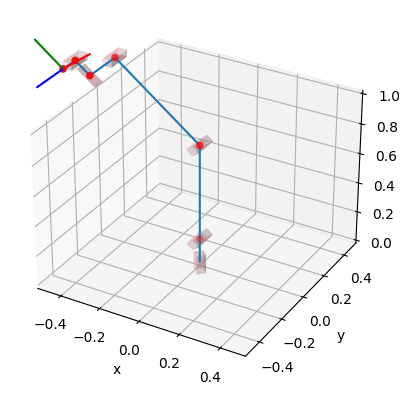

In [ ]:
dh_params = np.array([[0.163, 0., 0.5 * pi, 0.],
                      [0., 0.632, pi, 0.5 * pi],
                      [0., 0.6005, pi, 0.],
                      [0.2013, 0., -0.5 * pi, -0.5 * pi],
                      [0.1025, 0., 0.5 * pi, 0.],
                      [0.094, 0., 0., 0.]])
robot = RobotSerial(dh_params)

theta = np.array([0., 0., -0.25 * pi, 0., 0., 0.])
f = robot.forward(theta)
robot.show()

inverse is successful: True
axis values: 
[ 2.344 -0.422 -1.049  0.943 -1.571 -0.798]


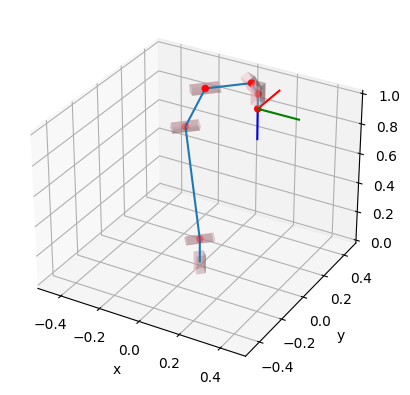

In [ ]:
import numpy as np
from math import pi


def main():
    np.set_printoptions(precision=3, suppress=True)

    dh_params = np.array([[0.163, 0., 0.5 * pi, 0.],
                          [0., 0.632, pi, 0.5 * pi],
                          [0., 0.6005, pi, 0.],
                          [0.2013, 0., -0.5 * pi, -0.5 * pi],
                          [0.1025, 0., 0.5 * pi, 0.],
                          [0.094, 0., 0., 0.]])

    robot = RobotSerial(dh_params)

    # =====================================
    # inverse
    # =====================================

    xyz = np.array([[0.28127], [0.], [1.13182]])
    abc = np.array([0.5 * pi, 0., pi])
    end = Frame.from_euler_3(abc, xyz)
    robot.inverse(end)

    print("inverse is successful: {0}".format(robot.is_reachable_inverse))
    print("axis values: \n{0}".format(robot.axis_values))
    robot.show()
    #robot.show(ws=True)

    # example of unsuccessful inverse kinematics
    #xyz = np.array([[2.2], [0.], [1.9]])
    #end = Frame.from_euler_3(abc, xyz)
    #robot.inverse(end)

    #print("inverse is successful: {0}".format(robot.is_reachable_inverse))


if __name__ == "__main__":
    main()

In [ ]:
!pip install -q ipympl

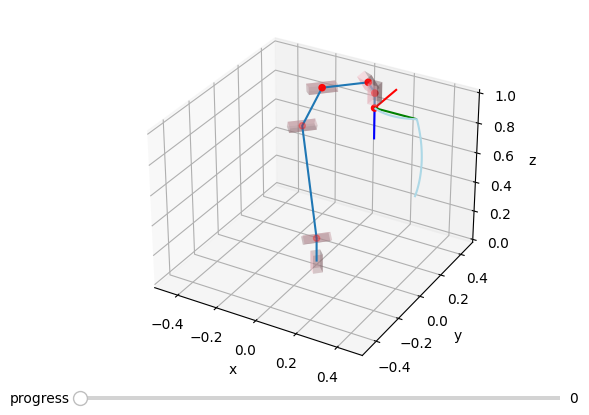

In [ ]:
#%matplotlib notebook
%matplotlib inline
#%matplotlib ipympl
#%matplotlib widget
#import mpld3
#mpld3.enable_notebook()

import numpy as np
from math import pi

#from matplotlib import rc
#rc('animation', html='jshtml')
#from IPython.core.interactiveshell import InteractiveShell
#InteractiveShell.ast_node_interactivity = "all"


def main():
    np.set_printoptions(precision=3, suppress=True)

    dh_params = np.array([[0.163, 0., 0.5 * pi, 0.],
                          [0., 0.632, pi, 0.5 * pi],
                          [0., 0.6005, pi, 0.],
                          [0.2013, 0., -0.5 * pi, -0.5 * pi],
                          [0.1025, 0., 0.5 * pi, 0.],
                          [0.094, 0., 0., 0.]])

    robot = RobotSerial(dh_params)

    # =====================================
    # trajectory
    # =====================================

    frames = [Frame.from_euler_3(np.array([0.5 * pi, 0., pi]), np.array([[0.28127], [0.], [1.13182]])),
              Frame.from_euler_3(np.array([0.25 * pi, 0., 0.75 * pi]), np.array([[0.48127], [0.], [1.13182]])),
              Frame.from_euler_3(np.array([0.5 * pi, 0., pi]), np.array([[0.48127], [0.], [0.63182]]))]
    time_points = np.array([0., 6., 10.])
    trajectory = RobotTrajectory(robot, frames, time_points)

    trajectory.show(motion="p2p")

if __name__ == "__main__":
    main()

$r = p + Rr'$

$\dot{r} = \dot{p} + \dot{R}r'$

$R^{T}R = RR^{T} = E$

$\dot{R}R^{T}+R\dot{R^{T}} = 0$

$\dot{R} = \Lambda R$

$\Lambda + \Lambda^{T} = 0$

$\Lambda = -\Lambda^{T}$

$v_{M}=v_{0}+\dot{R}p= v_{0} + \Lambda{R}r'$

$v_{M}=v_{0}+\Lambda$

$\mathbf{v}_M = \mathbf{v}_0 + \Lambda \tilde{\mathbf{r}}$


$\Lambda = \begin{pmatrix} 0 & -\omega \\ \omega & 0 \end{pmatrix} = \omega \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$



Скалярную величину $\omega$, являющуюся параметром, который характеризует скорость вращения, называют угловой скоростью вращения, так что
$ \Lambda = \Lambda(\omega). $

Линейную скорость каждой точки с координатами $(x, y)$ можно найти следующим образом:
$ \mathbf{v} = \Lambda \mathbf{r} = \omega \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} x \\ y \end{pmatrix} = \begin{pmatrix} -\omega y \\ \omega x \end{pmatrix}. $

2. Вращение в пространстве $(n = 3)$. Кососимметрическая матрица вращений $\Lambda$ в этом случае имеет вид:
$ \Lambda = \begin{pmatrix} 0 & a & b \\ -a & 0 & c \\ -b & -c & 0 \end{pmatrix}, $
где тройки чисел $a, b, c$ характеризуют вращение. Тогда линейная скорость точки с координатами $(x, y, z)$ определяется соотношением
$ \mathbf{v} = \begin{pmatrix} 0 & a & b \\ -a & 0 & c \\ -b & -c & 0 \end{pmatrix} \begin{pmatrix} x \\ y \\ z \end{pmatrix} = \begin{pmatrix} a y + b z \\ c z - a x \\ -b x - c y \end{pmatrix}. \tag{3.9} $

В то же время в механике принято угловую скорость характеризовать вектором $\omega$, так что линейную скорость можно найти с использованием операции векторного умножения:
$ \mathbf{v} = \omega \times \mathbf{r} = \begin{pmatrix} -\omega_z y + \omega_y z \\ -\omega_x z + \omega_z x \\ -\omega_y x + \omega_x y \end{pmatrix}. \tag{3.10} $

Целесообразно выбрать параметры $a, b, c$, входящие в $(3.8)$, так, чтобы $(3.8)$ и $(3.9)$ совпадали:

$ \Lambda = \Lambda(\omega) = \begin{pmatrix} 0 & -\omega_z & \omega_y \\ \omega_z & 0 & -\omega_x \\ -\omega_y & \omega_x & 0 \end{pmatrix}. \tag{3.11} $



Положение тела (т. е. связанной системы координат) задается матрицей

$T = \begin{pmatrix} R & p \\ 000 & 1 \end{pmatrix},$ так что
$\rho = T \rho'$


Дифференцируя последнее соотношение, имеем

$\dot{\rho} = \dot{T} \rho'. \tag{3.13}$


Найдем матрицу $\dot{T}$ в форме, аналогичной (3.5):

$\dot{T} = W(\omega, v_0) T. \tag{3.14}$

В силу невырожденности матрицы  $T$ из (3.14) имеем
$ W(\omega, v_0) = \dot{T} T^{-1} = \begin{pmatrix} \dot{R} & \dot{p} \\ 000 & 0 \end{pmatrix}
\begin{pmatrix} R & p \\ 000 & 1 \end{pmatrix}^{-1} = \begin{pmatrix} \Lambda R & v_0 \\ 000 & 0 \end{pmatrix}
\begin{pmatrix} R^T & -R^T p \\ 000 & 1 \end{pmatrix},
$
или окончательно
$ W(\omega, v_0) = \begin{pmatrix} \Lambda(\omega) & -\Lambda(\omega) p + v_0 \\ 000 & 0 \end{pmatrix}. \tag{3.15}$

Из (3.13) с учетом (3.14) получаем соотношение
$\dot{\rho} = W(\omega, v_0) \rho, \tag{3.16}$
